<a href="https://colab.research.google.com/github/vaya75e/ai/blob/main/Ai_Week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ultralytics gdown

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 8.2 MB/s eta 0:00:00


In [ ]:
import ultralytics, torch
ultralytics.checks()
print('มีการ์ดจอให้ใช้ไหม', torch.cuda.is_available())

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)
มีการ์ดจอให้ใช้ไหม True


In [ ]:
import os, glob
ROOT = '/content/lpr'
FILE_ID = '1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt'      # รหัสของ lpr-week12-data.zip บน Google Drive ของอาจารย์
if not os.path.exists(f'{ROOT}/gate'):
    !gdown {FILE_ID} -O /content/lpr-week12-data.zip
    !unzip -q /content/lpr-week12-data.zip -d {ROOT}
for s in ['train', 'val', 'test']:
    print(f'gate/{s}', len(glob.glob(f'{ROOT}/gate/{s}/images/*')), 'ภาพ')
print('road', len(glob.glob(f'{ROOT}/road/images/*')), 'เฟรม')
print(open(f'{ROOT}/README.txt', encoding='utf-8').read())

Downloading...
From (original): https://drive.google.com/uc?id=1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt
From (redirected): https://drive.google.com/uc?id=1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt&confirm=t&uuid=baeb55ea-9b42-4213-ad85-21b5a856fa90
To: /content/lpr-week12-data.zip
100% 90.8M/90.8M [00:00<00:00, 94.3MB/s]
gate/train 140 ภาพ
gate/val 30 ภาพ
gate/test 30 ภาพ
road 139 เฟรม
ชุดข้อมูลสำหรับใบงานแล็บสัปดาห์ที่ 12 วิชา Artificial Intelligence (520 331)
gate/  ภาพรถหน้าลานจอด 200 ใบ แบ่ง train 140 / val 30 / test 30
       ที่มา Thailand License Plates (ThailLand-plates) บน Roboflow Universe สัญญาอนุญาต CC BY 4.0
road/  เฟรมจากวิดีโอกล้องหน้ารถในกรุงเทพ 139 เฟรมที่มีเฉลย (416 ป้าย) ย่อเป็น 1920x1080
       ที่มา Thai License Plate Detector (Cytron) บน Roboflow Universe สัญญาอนุญาต CC BY 4.0
labels/ เป็นรูปแบบ YOLO (class cx cy w h หรือรูปหลายเหลี่ยม) มีคลาสเดียวคือ plate
ชื่อไฟล์ของ road มีเลขเฟรม เช่น 1_mp4-213_jpg... เลขนี้คือลำดับเวลาในวิดีโอ



In [ ]:
import yaml, random, shutil, re
from PIL import Image

def make_yaml(name, train, val, test=None):
    """เขียนไฟล์บอก YOLO ว่าชุดฝึก ชุดตรวจ ชุดสอบ อยู่โฟลเดอร์ไหน (ใช้ path เต็ม)"""
    d = {'path': ROOT, 'train': train, 'val': val, 'names': {0: 'plate'}}
    if test: d['test'] = test
    p = f'{ROOT}/{name}.yaml'
    yaml.safe_dump(d, open(p, 'w'))
    return p

def read_boxes(label_path):
    """อ่านเฉลยหนึ่งไฟล์ คืนกรอบเป็น (cx, cy, w, h) สัดส่วนของภาพ รองรับทั้งกรอบและรูปหลายเหลี่ยม"""
    boxes = []
    for line in open(label_path):
        v = list(map(float, line.split()[1:]))
        if len(v) == 4:
            boxes.append(tuple(v))
        else:
            xs, ys = v[0::2], v[1::2]
            boxes.append(((min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)))
    return boxes

def label_of(img_path):
    return img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'

def link_subset(src_imgs, dst):
    """สร้างโฟลเดอร์ชุดข้อมูลใหม่จากรายชื่อภาพ โดยคัดลอกทั้งภาพและเฉลย"""
    os.makedirs(f'{dst}/images', exist_ok=True); os.makedirs(f'{dst}/labels', exist_ok=True)
    for p in src_imgs:
        shutil.copy(p, f'{dst}/images/'); shutil.copy(label_of(p), f'{dst}/labels/')
    return dst

gate_yaml = make_yaml('gate', 'gate/train/images', 'gate/val/images', 'gate/test/images')
print(open(gate_yaml).read())

names:
  0: plate
path: /content/lpr
test: gate/test/images
train: gate/train/images
val: gate/val/images



In [ ]:
import yaml, random, shutil, re
from PIL import Image

def make_yaml(name, train, val, test=None):
    """เขียนไฟล์บอก YOLO ว่าชุดฝึก ชุดตรวจ ชุดสอบ อยู่โฟลเดอร์ไหน (ใช้ path เต็ม)"""
    d = {'path': ROOT, 'train': train, 'val': val, 'names': {0: 'plate'}}
    if test: d['test'] = test
    p = f'{ROOT}/{name}.yaml'
    yaml.safe_dump(d, open(p, 'w'))
    return p

def read_boxes(label_path):
    """อ่านเฉลยหนึ่งไฟล์ คืนกรอบเป็น (cx, cy, w, h) สัดส่วนของภาพ รองรับทั้งกรอบและรูปหลายเหลี่ยม"""
    boxes = []
    for line in open(label_path):
        v = list(map(float, line.split()[1:]))
        if len(v) == 4:
            boxes.append(tuple(v))
        else:
            xs, ys = v[0::2], v[1::2]
            boxes.append(((min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)))
    return boxes

def label_of(img_path):
    return img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'

def link_subset(src_imgs, dst):
    """สร้างโฟลเดอร์ชุดข้อมูลใหม่จากรายชื่อภาพ โดยคัดลอกทั้งภาพและเฉลย"""
    os.makedirs(f'{dst}/images', exist_ok=True); os.makedirs(f'{dst}/labels', exist_ok=True)
    for p in src_imgs:
        shutil.copy(p, f'{dst}/images/'); shutil.copy(label_of(p), f'{dst}/labels/')
    return dst

gate_yaml = make_yaml('gate', 'gate/train/images', 'gate/val/images', 'gate/test/images')
print(open(gate_yaml).read())

names:
  0: plate
path: /content/lpr
test: gate/test/images
train: gate/train/images
val: gate/val/images



ด่านที่ 1 **สมองที่ยังไม่รู้จักคำว่าป้าย**

In [ ]:
from ultralytics import YOLO
from collections import Counter
coco = YOLO('yolov8n.pt')                       # สมองที่ฝึกกับ COCO มาแล้ว ดาวน์โหลดอัตโนมัติ
test_imgs = sorted(glob.glob(f'{ROOT}/gate/test/images/*'))
results = coco.predict(test_imgs, imgsz=640, conf=0.25, verbose=False)
count = Counter(coco.names[int(c)] for r in results for c in r.boxes.cls)
print('กรอบที่ตีได้ทั้งหมด', sum(count.values()))
print(count)
print('มีคำว่า license plate ในพจนานุกรม 80 คำไหม', any('plate' in n for n in coco.names.values()))

กรอบที่ตีได้ทั้งหมด 62
Counter({'car': 40, 'truck': 14, 'motorcycle': 2, 'person': 2, 'bus': 2, 'potted plant': 1, 'bicycle': 1})
มีคำว่า license plate ในพจนานุกรม 80 คำไหม False


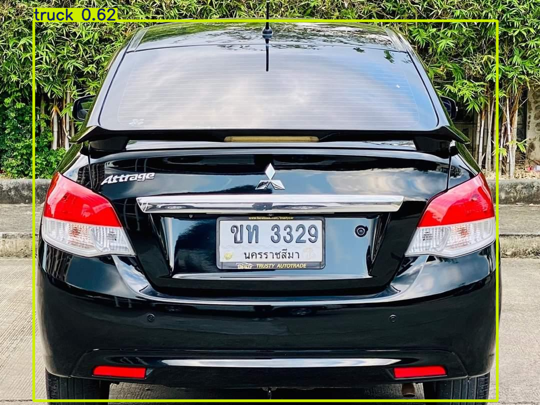

In [ ]:
from IPython.display import display
display(Image.fromarray(results[10].plot()[:, :, ::-1]).resize((540, 405)))

ด่านที่ 2 **รู้จักข้อมูลก่อนฝึก**

In [ ]:
import numpy as np
widths = []
for p in glob.glob(f'{ROOT}/gate/train/images/*'):
    for cx, cy, w, h in read_boxes(label_of(p)):
        widths.append(w)
widths = np.array(widths) * 100
print('ป้ายในชุดฝึก', len(widths), 'ใบ')
print('กว้างกลางๆ %.1f%% ของภาพ  เล็กสุด %.1f%%  ใหญ่สุด %.1f%%' % (np.median(widths), widths.min(), widths.max()))

ป้ายในชุดฝึก 141 ใบ
กว้างกลางๆ 14.3% ของภาพ  เล็กสุด 5.3%  ใหญ่สุด 25.4%


ด่านที่ 3 **ยืมตาแล้วปรับทั้งตัว**



In [ ]:
ft = YOLO('yolov8n.pt')
ft.train(data=gate_yaml, epochs=30, imgsz=640, batch=8, seed=0,
         project=f'{ROOT}/runs', name='finetune', exist_ok=True, plots=False, verbose=False)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/gate.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f4e4c89b690>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

รอบแรก 38  รอบที่ 7 100  รอบสุดท้าย 99.3


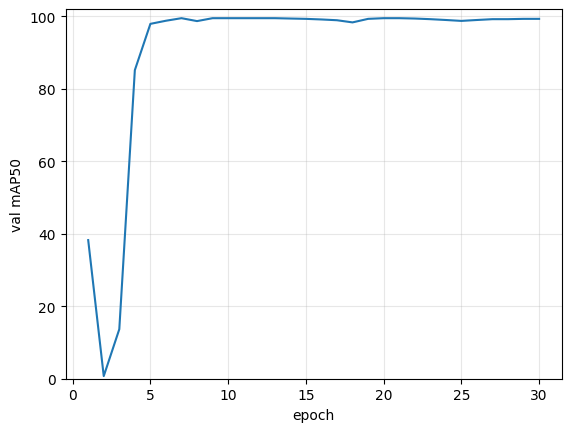

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def curve(run):
    df = pd.read_csv(f'{ROOT}/runs/{run}/results.csv')
    df.columns = [c.strip() for c in df.columns]
    return df['metrics/mAP50(B)'].values * 100

m = curve('finetune')
print('รอบแรก %.0f  รอบที่ 7 %.0f  รอบสุดท้าย %.1f' % (m[0], m[6], m[-1]))
plt.plot(range(1, len(m)+1), m); plt.xlabel('epoch'); plt.ylabel('val mAP50'); plt.ylim(0, 102); plt.grid(alpha=.3); plt.show()

In [ ]:
def score(weights, data, split='val'):
    r = YOLO(weights).val(data=data, split=split, imgsz=640, batch=8, plots=False, verbose=False)
    return r.box.map50 * 100, r.box.map * 100

ft_test = score(f'{ROOT}/runs/finetune/weights/best.pt', gate_yaml, 'test')
print('ชุดสอบ  mAP50 %.1f   mAP50-95 %.1f' % ft_test)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2080.8±397.5 MB/s, size: 212.2 KB)
val: Scanning /content/lpr/gate/test/labels... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 1.1Kit/s 0.0s
val: New cache created: /content/lpr/gate/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 30. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 4.8it/s 0.8s
                   all         30         30      0.997          1      0.995       0.84
Speed: 1.1ms preprocess, 10.0ms inference, 0.0ms loss, 2.4ms postprocess per image
ชุด

ด่านที่ 4 **อีกสองวิธีที่เหลือ**

In [ ]:
scratch = YOLO('yolov8n.yaml')                  # โครงสร้างเดียวกัน แต่น้ำหนักเริ่มจากค่าสุ่ม
scratch.train(data=gate_yaml, epochs=30, imgsz=640, batch=8, seed=0, pretrained=False,
              project=f'{ROOT}/runs', name='scratch', exist_ok=True, plots=False, verbose=False)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/gate.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=scratch, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f503a7270e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

งานของด่านนี้

In [ ]:
frozen = YOLO('yolov8n.pt')
frozen.train(data=gate_yaml, epochs=30, imgsz=640, batch=8, seed=0, freeze=10,   # ล็อก 10 ชั้นแรก คือส่วนตา
             project=f'{ROOT}/runs', name='frozen', exist_ok=True, plots=False, verbose=False)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/gate.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=frozen, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f4dfcc96890>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3074.3±665.9 MB/s, size: 212.2 KB)
val: Scanning /content/lpr/gate/test/labels.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 8.4Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 30. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.2it/s 0.6s
                   all         30         30      0.958      0.967      0.977      0.646
Speed: 1.2ms preprocess, 5.9ms inference, 0.0ms loss, 2.0ms postprocess per image
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 

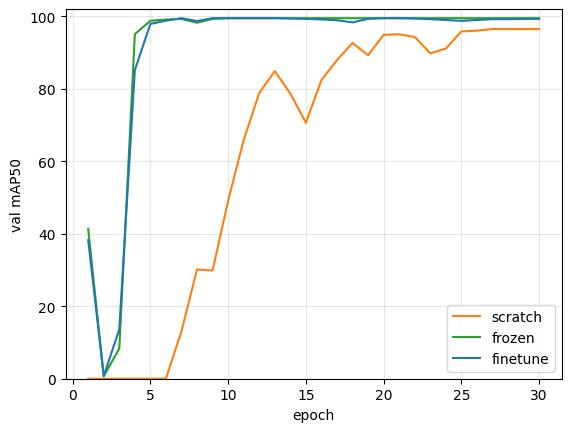

In [ ]:
rows = []
for run, label in [('scratch', 'เริ่มจากศูนย์'), ('frozen', 'ยืมตาแล้วตรึง'), ('finetune', 'ยืมตาแล้วปรับทั้งตัว')]:
    m50, m5095 = score(f'{ROOT}/runs/{run}/weights/best.pt', gate_yaml, 'test')
    c = curve(run)
    stable = next((i + 1 for i in range(len(c)) if (c[i:] >= 94).all()), None)   # รอบแรกที่ยืนเหนือ 94 ได้ถาวร
    rows.append((label, c[0], '-' if stable is None else str(stable), m50, m5095))
print('%-22s %8s %12s %10s %10s' % ('วิธี', 'รอบแรก', 'ยืนเหนือ 94', 'mAP50', 'mAP50-95'))
for r in rows:
    print('%-22s %8.0f %12s %10.1f %10.1f' % r)
for run, c in [('scratch', 'tab:orange'), ('frozen', 'tab:green'), ('finetune', 'tab:blue')]:
    m = curve(run); plt.plot(range(1, len(m)+1), m, color=c, label=run)
plt.xlabel('epoch'); plt.ylabel('val mAP50'); plt.ylim(0, 102); plt.grid(alpha=.3); plt.legend(); plt.show()

ด่านที่ 5 **ยี่สิบใบก็พอไหม**

In [ ]:
random.seed(2569)
pick = random.sample(sorted(glob.glob(f'{ROOT}/gate/train/images/*')), 20)
link_subset(pick, f'{ROOT}/gate20/train')
gate20_yaml = make_yaml('gate20', 'gate20/train/images', 'gate/val/images', 'gate/test/images')
few = YOLO('yolov8n.pt')
few.train(data=gate20_yaml, epochs=30, imgsz=640, batch=8, seed=0,
          project=f'{ROOT}/runs', name='few20', exist_ok=True, plots=False, verbose=False)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/gate20.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=few20, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f4dfb2a50f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
print('20 ใบ   ชุดสอบ mAP50 %.1f   mAP50-95 %.1f' % score(f'{ROOT}/runs/few20/weights/best.pt', gate_yaml, 'test'))
print('140 ใบ  ชุดสอบ mAP50 %.1f   mAP50-95 %.1f' % ft_test)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3801.7±603.8 MB/s, size: 205.3 KB)
val: Scanning /content/lpr/gate/test/labels.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 7.4Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 30. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.8it/s 0.7s
                   all         30         30          1      0.842      0.947      0.762
Speed: 1.5ms preprocess, 5.1ms inference, 0.0ms loss, 3.1ms postprocess per image
20 ใบ   ชุดสอบ mAP50 94.7   mAP50-95 76.2
140 ใบ  ชุดสอบ m

ด่านที่ 6 วันแรกที่ย้ายไปหน้างานจริง

In [ ]:
road_yaml = make_yaml('road', 'road/images', 'road/images')
road_all = score(f'{ROOT}/runs/finetune/weights/best.pt', road_yaml)
print('หน้าลานจอด mAP50 %.1f   บนถนน mAP50 %.1f' % (ft_test[0], road_all[0]))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4172.4±510.2 MB/s, size: 393.5 KB)
val: Scanning /content/lpr/road/labels... 139 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 139/139 1.9Kit/s 0.1s
val: New cache created: /content/lpr/road/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 8.0it/s 2.3s
                   all        139        416      0.581      0.101      0.109     0.0511
Speed: 0.9ms preprocess, 4.7ms inference, 0.0ms loss, 2.3ms postprocess per image
หน้าลานจอด mAP50 99.5   บนถนน mAP50 10.9


In [ ]:
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter)

model = YOLO(f'{ROOT}/runs/finetune/weights/best.pt')
found, missed = [], []
for p in sorted(glob.glob(f'{ROOT}/road/images/*')):
    W, H = Image.open(p).size
    dets = [[float(v) for v in b] for b in model.predict(p, imgsz=640, conf=0.25, verbose=False)[0].boxes.xyxy]
    for cx, cy, w, h in read_boxes(label_of(p)):
        g = [(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H]
        (found if any(iou(d, g) >= 0.5 for d in dets) else missed).append(w * 100)
print('ป้ายทั้งหมด', len(found)+len(missed), 'ใบ  หาเจอ', len(found), 'ใบ')
print('ความกว้างกลางๆ ของป้ายที่เจอ %.1f%%  ที่พลาด %.1f%%' % (np.median(found), np.median(missed)))
for lo, hi in [(0, 1), (1, 2), (2, 3), (3, 5), (5, 100)]:
    f = sum(lo <= x < hi for x in found); m = sum(lo <= x < hi for x in missed)
    print('ป้ายกว้าง %2d-%-3d%%  ทั้งหมด %3d  เจอ %2d' % (lo, hi, f+m, f))

ป้ายทั้งหมด 416 ใบ  หาเจอ 29 ใบ
ความกว้างกลางๆ ของป้ายที่เจอ 5.8%  ที่พลาด 2.2%
ป้ายกว้าง  0-1  %  ทั้งหมด  23  เจอ  0
ป้ายกว้าง  1-2  %  ทั้งหมด 149  เจอ  0
ป้ายกว้าง  2-3  %  ทั้งหมด  81  เจอ  0
ป้ายกว้าง  3-5  %  ทั้งหมด 102  เจอ  7
ป้ายกว้าง  5-100%  ทั้งหมด  61  เจอ 22


ด่านที่ 7 ยาแก้ ผลข้างเคียง และวิธีแก้ผลข้างเคียง



In [ ]:
frame_no = lambda p: int(re.search(r'-(\d+)_jpg', p).group(1))
road_imgs = sorted(glob.glob(f'{ROOT}/road/images/*'), key=frame_no)
early = [p for p in road_imgs if frame_no(p) < 213]
late  = [p for p in road_imgs if frame_no(p) >= 213]
link_subset(early, f'{ROOT}/road_time/train'); link_subset(late, f'{ROOT}/road_time/val')
road_time_yaml = make_yaml('road_time', 'road_time/train/images', 'road_time/val/images')
print('ชุดฝึก', len(early), 'เฟรม (เฟรมที่ %d ถึง %d)' % (frame_no(early[0]), frame_no(early[-1])))
print('ชุดตรวจ', len(late), 'เฟรม (เฟรมที่ %d ถึง %d)' % (frame_no(late[0]), frame_no(late[-1])))
print('ก่อนปรับ  ชุดตรวจบนถนน mAP50 %.1f' % score(f'{ROOT}/runs/finetune/weights/best.pt', road_time_yaml)[0])

ชุดฝึก 95 เฟรม (เฟรมที่ 3 ถึง 211)
ชุดตรวจ 44 เฟรม (เฟรมที่ 213 ถึง 307)
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4026.8±389.5 MB/s, size: 319.4 KB)
val: Scanning /content/lpr/road_time/val/labels... 44 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 2.0Kit/s 0.0s
val: New cache created: /content/lpr/road_time/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 6.3it/s 0.9s
                   all         44        121      0.858       0.15        0.2     0.0926
Speed: 1.1ms preprocess, 5.8ms inference, 0.0ms loss, 2.7ms postprocess per image
ก่อนปรับ  ชุดตรวจบนถนน mAP50 20.0


In [ ]:
adapt = YOLO(f'{ROOT}/runs/finetune/weights/best.pt')    # เริ่มจากสมองที่เก่งหน้าลานจอดแล้ว
adapt.train(data=road_time_yaml, epochs=12, imgsz=640, batch=8, seed=0,
            project=f'{ROOT}/runs', name='roadadapt', exist_ok=True, plots=False, verbose=False)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/road_time.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/lpr/runs/finetune/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=roadadapt, nbs=64, nms=None, ops

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f4df6504d00>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
w = f'{ROOT}/runs/roadadapt/weights/best.pt'
print('หลังปรับ  ชุดตรวจบนถนน mAP50 %.1f' % score(w, road_time_yaml)[0])
print('หลังปรับ  ชุดสอบหน้าลานจอด mAP50 %.1f   (ก่อนปรับ %.1f)' % (score(w, gate_yaml, 'test')[0], ft_test[0]))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4512.7±650.1 MB/s, size: 372.3 KB)
val: Scanning /content/lpr/road_time/val/labels.cache... 44 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 11.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 6.4it/s 0.9s
                   all         44        121      0.629      0.505       0.51      0.165
Speed: 1.0ms preprocess, 4.7ms inference, 0.0ms loss, 2.6ms postprocess per image
หลังปรับ  ชุดตรวจบนถนน mAP50 51.0
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2351.0±388.2 MB/s, size: 153.6 KB)
val: Scanning /content/lpr/gate/test/la

In [ ]:
link_subset(glob.glob(f'{ROOT}/gate/train/images/*') + early, f'{ROOT}/mix/train')
mix_yaml = make_yaml('mix', 'mix/train/images', 'road_time/val/images')
mix = YOLO(f'{ROOT}/runs/finetune/weights/best.pt')
mix.train(data=mix_yaml, epochs=12, imgsz=640, batch=8, seed=0,
          project=f'{ROOT}/runs', name='mix', exist_ok=True, plots=False, verbose=False)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/mix.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/lpr/runs/finetune/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=mix, nbs=64, nms=None, opset=None, opt

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f4df6269e80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
w = f'{ROOT}/runs/mix/weights/best.pt'
print('ซ้อมทวน  ชุดตรวจบนถนน mAP50 %.1f' % score(w, road_time_yaml)[0])
print('ซ้อมทวน  ชุดสอบหน้าลานจอด mAP50 %.1f' % score(w, gate_yaml, 'test')[0])

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4053.9±926.6 MB/s, size: 328.7 KB)
val: Scanning /content/lpr/road_time/val/labels.cache... 44 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 11.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 7.2it/s 0.8s
                   all         44        121      0.613      0.405      0.482      0.201
Speed: 0.9ms preprocess, 3.8ms inference, 0.0ms loss, 2.3ms postprocess per image
ซ้อมทวน  ชุดตรวจบนถนน mAP50 48.2
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3118.4±871.1 MB/s, size: 184.5 KB)
val: Scanning /content/lpr/gate/test/lab

ด่านที่ 8 มุมยุค AI อย่าเพิ่งเชื่อผู้เขียน

In [ ]:
hot = YOLO('yolov8n.pt')
hot.train(data=gate_yaml, epochs=15, imgsz=640, batch=8, seed=0,
          optimizer='SGD', lr0=0.1, warmup_epochs=0,        # ก้าวใหญ่ห้าสิบเท่า ไม่วอร์มอัพ
          project=f'{ROOT}/runs', name='hotlr', exist_ok=True, plots=False, verbose=False)
print('คะแนนชุดตรวจแต่ละรอบ', [round(x) for x in curve('hotlr')])
print('ชุดสอบหน้าลานจอด %.1f   บนถนน %.1f' % (score(f'{ROOT}/runs/hotlr/weights/best.pt', gate_yaml, 'test')[0],
                                             score(f'{ROOT}/runs/hotlr/weights/best.pt', road_yaml)[0]))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/gate.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.1, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hotlr, nbs=64, nms=None, opset=None, optimize=False, optimizer=SGD, ov

In [ ]:
random.seed(2569)
shuffled = road_imgs[:]; random.shuffle(shuffled)
link_subset(shuffled[:len(early)], f'{ROOT}/road_rand/train'); link_subset(shuffled[len(early):], f'{ROOT}/road_rand/val')
road_rand_yaml = make_yaml('road_rand', 'road_rand/train/images', 'road_rand/val/images')
rnd = YOLO(f'{ROOT}/runs/finetune/weights/best.pt')
rnd.train(data=road_rand_yaml, epochs=12, imgsz=640, batch=8, seed=0,
          project=f'{ROOT}/runs', name='roadrand', exist_ok=True, plots=False, verbose=False)
print('สุ่มแบ่ง     ชุดตรวจของตัวเอง mAP50 %.1f' % score(f'{ROOT}/runs/roadrand/weights/best.pt', road_rand_yaml)[0])
print('แบ่งตามเวลา ชุดตรวจของตัวเอง mAP50 %.1f' % score(f'{ROOT}/runs/roadadapt/weights/best.pt', road_time_yaml)[0])
print('แบ่งตามเวลา สอบกับเฟรมที่เคยฝึก mAP50 %.1f' % score(f'{ROOT}/runs/roadadapt/weights/best.pt', road_time_yaml, 'train')[0])

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr/road_rand.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/lpr/runs/finetune/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=roadrand, nbs=64, nms=None, opse

#Lab week 8 ทำต่อจาก week 7

เซลล์ตั้งต้น

In [1]:
!pip -q install ultralytics easyocr gdown
!apt-get -qq install -y fonts-thai-tlwg > /dev/null      # ฟอนต์ไทยสำหรับกราฟ
import torch, ultralytics
print('มีการ์ดจอให้ใช้ไหม', torch.cuda.is_available())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 12.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
มีการ์ดจอให้ใช้ไหม True


In [2]:
import os, glob
ROOT = '/content/lpr'
FILE_ID = '1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt'           # lpr-week12-data.zip ชุดเดิมจากสัปดาห์ที่แล้ว
FILE_ID_W13 = '1aHz3xiJq3TcNv7nPTmBrr6d53F4ZclEv'        # lpr-week13-extra.zip มี best.pt กับเฉลยทะเบียน
if not os.path.exists(f'{ROOT}/gate'):
    !gdown {FILE_ID} -O /content/lpr-week12-data.zip
    !unzip -q /content/lpr-week12-data.zip -d {ROOT}
if not os.path.exists(f'{ROOT}/week13'):
    !gdown {FILE_ID_W13} -O /content/lpr-week13-extra.zip
    !unzip -q /content/lpr-week13-extra.zip -d {ROOT}
test_imgs = sorted(glob.glob(f'{ROOT}/gate/test/images/*'))
print('ภาพสอบ', len(test_imgs), 'ใบ')
print(open(f'{ROOT}/week13/README.txt', encoding='utf-8').read())

Downloading...
From (original): https://drive.google.com/uc?id=1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt
From (redirected): https://drive.google.com/uc?id=1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt&confirm=t&uuid=1d0f17ff-b22e-44fc-9254-24b994088ebe
To: /content/lpr-week12-data.zip
100% 90.8M/90.8M [00:00<00:00, 151MB/s]
Downloading...
From: https://drive.google.com/uc?id=1aHz3xiJq3TcNv7nPTmBrr6d53F4ZclEv
To: /content/lpr-week13-extra.zip
100% 5.65M/5.65M [00:00<00:00, 119MB/s]
ภาพสอบ 30 ใบ
lpr-week13-extra.zip
best.pt    สมองหาป้าย YOLOv8n ที่ซ้อมทวนด้วยภาพ gate/train 140 ใบ 30 รอบ (finetune จากสัปดาห์ที่ 12)
labels.csv เฉลยทะเบียนและจังหวัดของภาพ gate/test 30 ใบ ที่ผู้สอนอ่านด้วยตาเอง
           ใบที่จังหวัดว่างคือใบที่อ่านไม่ออก



In [3]:
import csv, re, unicodedata, time
import numpy as np
from PIL import Image

LABEL = {r['file']: r for r in csv.DictReader(open(f'{ROOT}/week13/labels.csv', encoding='utf-8'))}
TH_DIGIT = str.maketrans('๐๑๒๓๔๕๖๗๘๙', '0123456789')

def normalize(s):
    """ตัดช่องว่าง ขีด จุด และแปลงเลขไทยเป็นอารบิก ไม่แก้ตัวอักษรใดๆ"""
    return re.sub(r'[\s\-\.]', '', unicodedata.normalize('NFC', s)).translate(TH_DIGIT)

def crop_plate(path, box, pad=0):
    """ตัดภาพตามกรอบ (x0,y0,x1,y1) เผื่อขอบรอบด้าน pad จุด"""
    im = Image.open(path).convert('RGB'); W, H = im.size
    x0, y0, x1, y1 = box
    return im.crop((max(0, x0 - pad), max(0, y0 - pad), min(W, x1 + pad), min(H, y1 + pad)))

def parse(boxes, crop_height):
    """กล่องที่จุดกึ่งกลางอยู่เหนือ 58% ของความสูง = ทะเบียน ที่เหลือ = จังหวัด
    คืน (ทะเบียน, จังหวัดดิบ, ความมั่นใจต่ำสุดของกล่องทะเบียน)"""
    top = [b for b in boxes if np.mean([p[1] for p in b[0]]) < 0.58 * crop_height]
    bot = [b for b in boxes if np.mean([p[1] for p in b[0]]) >= 0.58 * crop_height]
    top.sort(key=lambda b: min(p[0] for p in b[0])); bot.sort(key=lambda b: min(p[0] for p in b[0]))
    reg = normalize(''.join(b[1] for b in top))
    prov = normalize(''.join(b[1] for b in bot))
    conf = min([float(b[2]) for b in top], default=0.0)
    return reg, prov, conf

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
for f in glob.glob('/usr/share/fonts/**/Loma*', recursive=True): fm.fontManager.addfont(f)
plt.rcParams['font.family'] = 'Loma'
GREEN, RED, ORANGE, GRAY = '#5f7a4a', '#b23b3b', '#b45309', '#9a948a'
print('เฉลย', len(LABEL), 'ใบ ตัวอย่าง', list(LABEL.values())[0])

เฉลย 30 ใบ ตัวอย่าง {'file': '20220516203717-34bc_wm_jpg.rf.e6a73a3015991de951d40f3ff79bc836.jpg', 'registration': '7กล9108', 'province': 'กรุงเทพมหานคร'}


ด่านที่ 1 สมองหาป้ายส่งกรอบให้สมองอ่านหนังสือ

In [4]:
from ultralytics import YOLO
finder = YOLO(f'{ROOT}/week13/best.pt')         # สมองหาป้ายจากสัปดาห์ที่แล้ว ถ้ามีของตัวเองก็ใช้ของตัวเองได้
BOX = {}
for p in test_imgs:
    r = finder.predict(p, imgsz=640, conf=0.25, verbose=False)[0]
    k = int(r.boxes.conf.argmax())                               # เอากรอบที่มั่นใจที่สุดหนึ่งกรอบต่อภาพ
    BOX[p] = [round(v) for v in r.boxes.xyxy[k].tolist()]
widths = [b[2] - b[0] for b in BOX.values()]
print('หาป้ายเจอ', len(BOX), 'จาก', len(test_imgs), 'ใบ  กรอบกว้าง', min(widths), 'ถึง', max(widths), 'จุด')

หาป้ายเจอ 30 จาก 30 ใบ  กรอบกว้าง 96 ถึง 275 จุด


In [5]:
import easyocr
t0 = time.time()
reader = easyocr.Reader(['th', 'en'], gpu=torch.cuda.is_available())
print('โหลดสมองอ่านหนังสือ %.1f วินาที' % (time.time() - t0))

p = test_imgs[2]                                 # ป้าย 1กฒ1753 ที่บทใช้เป็นตัวอย่าง
crop = crop_plate(p, BOX[p])
t0 = time.time(); boxes = reader.readtext(np.array(crop)); dt = time.time() - t0
print('อ่าน %.2f วินาที ได้ %d กล่อง' % (dt, len(boxes)))
for pts, text, conf in boxes:
    y = np.mean([q[1] for q in pts])
    print('%-16s มั่นใจ %.2f   กึ่งกลางสูง %.0f%% ของภาพ' % (text, conf, 100 * y / crop.height))

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Completeโหลดสมองอ่านหนังสือ 10.3 วินาที
อ่าน 0.54 วินาที ได้ 4 กล่อง
1753             มั่นใจ 1.00   กึ่งกลางสูง 32% ของภาพ
กรุงเทหมหานคร    มั่นใจ 0.41   กึ่งกลางสูง 62% ของภาพ
เกฒ              มั่นใจ 0.13   กึ่งกลางสูง 36% ของภาพ
wakaaty          มั่นใจ 0.04   กึ่งกลางสูง 76% ของภาพ


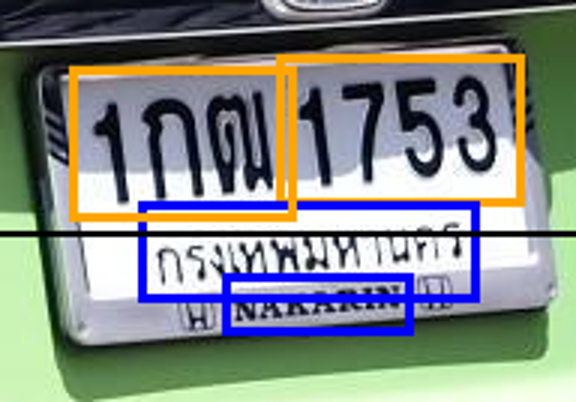

In [6]:
from PIL import ImageDraw
from IPython.display import display
im = crop.copy(); d = ImageDraw.Draw(im)
for pts, text, conf in boxes:
    xs = [q[0] for q in pts]; ys = [q[1] for q in pts]
    top = np.mean(ys) < 0.58 * crop.height
    d.rectangle([min(xs), min(ys), max(xs), max(ys)], outline='orange' if top else 'blue', width=3)
d.line([0, 0.58 * crop.height, crop.width, 0.58 * crop.height], fill='black', width=2)
display(im.resize((im.width * 3, im.height * 3)))

ด่านที่ 2 กติกาเส้นแบ่ง

In [7]:
reg, prov, conf = parse(boxes, crop.height)
print('ทะเบียนที่อ่านได้', reg, ' จังหวัดดิบ', prov, ' มั่นใจต่ำสุดของทะเบียน %.2f' % conf)
print('ทะเบียนจริง      ', LABEL[os.path.basename(p)]['registration'])

ทะเบียนที่อ่านได้ เกฒ1753  จังหวัดดิบ กรุงเทหมหานครwakaaty  มั่นใจต่ำสุดของทะเบียน 0.13
ทะเบียนจริง       1กฒ1753


ด่านที่ 3 อ่านป้ายสอบทั้ง 30 ใบ

In [8]:
import pandas as pd
rows = []
for p in test_imgs:
    crop = crop_plate(p, BOX[p])
    t0 = time.time(); boxes = reader.readtext(np.array(crop)); dt = time.time() - t0
    reg, prov, conf = parse(boxes, crop.height)
    truth = LABEL[os.path.basename(p)]['registration']
    rows.append(dict(file=os.path.basename(p)[:14], read=reg, truth=truth, ok=reg == truth,
                     digits_ok=re.sub(r'\D', '', reg) == re.sub(r'\D', '', truth),
                     letters_ok=re.sub(r'[^ก-ฮ]', '', reg) == re.sub(r'[^ก-ฮ]', '', truth),
                     conf=round(conf, 2), width=BOX[p][2] - BOX[p][0], sec=round(dt, 2)))
df = pd.DataFrame(rows)
print(df.to_string(index=False))
print()
print('ถูกทั้งป้าย %d/30   ตัวเลขถูกหมด %d/30   พยัญชนะไทยถูกหมด %d/30   เวลากลางๆ %.2f วินาทีต่อใบ'
      % (df.ok.sum(), df.digits_ok.sum(), df.letters_ok.sum(), df.sec.median()))

          file        read   truth    ok  digits_ok  letters_ok  conf  width  sec
20220516203717     7กล9108 7กล9108  True       True        True  0.97    173 0.18
20220516203721     7กล9108 7กล9108  True       True        True  0.98    176 0.16
20220718185915     เกฒ1753 1กฒ1753 False      False        True  0.13    192 0.30
20220728170738     9กฮ5961 9กฮ5961  True       True        True  0.99    174 0.14
20220728170738     9กฮ5961 9กฮ5961  True       True        True  0.99    275 0.20
20220728170739     9กฮ5961 9กฮ5961  True       True        True  0.98    166 0.16
20220819160212      ตกกาง( 6กก2536 False      False       False  0.05    162 0.14
20220914232916      พม1111  พม1111  True       True        True  0.70    180 0.28
20220915212650     8กค1018 8กค1018  True       True        True  0.56    153 0.33
20220916113635     9กด9225 9กด9225  True       True        True  0.39    134 0.20
20220918144959      ขท3329  ขท3329  True       True        True  0.83    217 0.23
20220921114511  

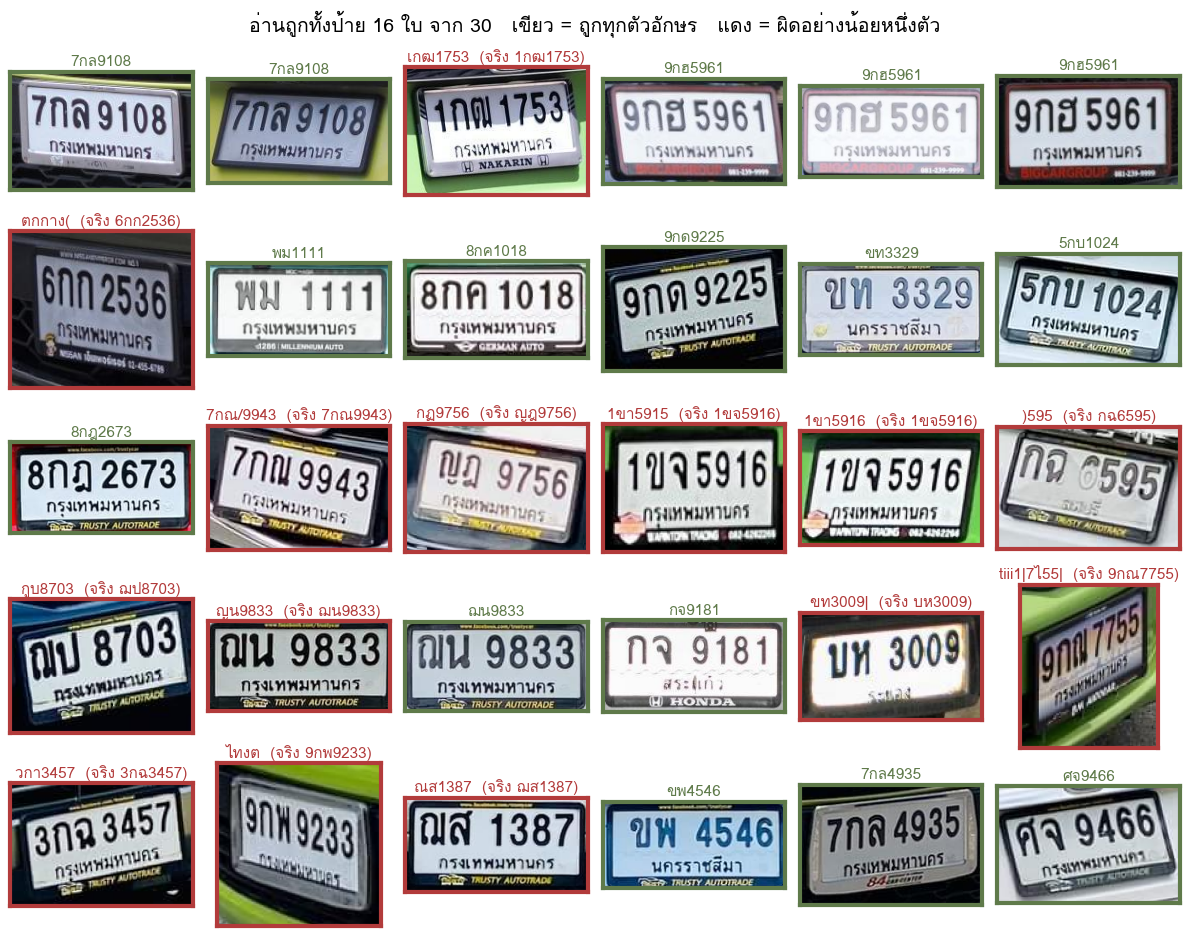

In [9]:
fig, axes = plt.subplots(5, 6, figsize=(12, 9.5))
for ax, p, r in zip(axes.flat, test_imgs, rows):
    ax.imshow(crop_plate(p, BOX[p])); ax.set_xticks([]); ax.set_yticks([])
    c = GREEN if r['ok'] else RED
    for sp in ax.spines.values(): sp.set_edgecolor(c); sp.set_linewidth(3)
    ax.set_title(r['read'] if r['ok'] else '%s  (จริง %s)' % (r['read'], r['truth']), fontsize=11, color=c, pad=4)
fig.suptitle('อ่านถูกทั้งป้าย %d ใบ จาก 30   เขียว = ถูกทุกตัวอักษร   แดง = ผิดอย่างน้อยหนึ่งตัว' % df.ok.sum(), fontsize=14)
plt.tight_layout(); plt.show()

In [10]:
small = df[df.width < 150]; big = df[df.width >= 150]
print('ป้ายแคบกว่า 150 จุด  อ่านถูก %d จาก %d' % (small.ok.sum(), len(small)))
print('ป้าย 150 จุดขึ้นไป   อ่านถูก %d จาก %d' % (big.ok.sum(), len(big)))

ป้ายแคบกว่า 150 จุด  อ่านถูก 1 จาก 9
ป้าย 150 จุดขึ้นไป   อ่านถูก 15 จาก 21


ด่านที่ 4 ความมั่นใจที่เชื่อไม่ได้

In [11]:
for th in [0.5, 0.8, 0.9]:
    passed = df[df.conf >= th]
    print('เส้นความมั่นใจ %.1f  ผ่าน %2d ใบ  ในนั้นผิด %d ใบ  อ่านถูกแต่ถูกทิ้ง %d ใบ'
          % (th, len(passed), (~passed.ok).sum(), (df.ok & (df.conf < th)).sum()))
wrong_but_sure = df[(~df.ok) & (df.conf >= 0.8)]
print(wrong_but_sure[['file', 'read', 'truth', 'conf']].to_string(index=False))

เส้นความมั่นใจ 0.5  ผ่าน 18 ใบ  ในนั้นผิด 4 ใบ  อ่านถูกแต่ถูกทิ้ง 2 ใบ
เส้นความมั่นใจ 0.8  ผ่าน 10 ใบ  ในนั้นผิด 1 ใบ  อ่านถูกแต่ถูกทิ้ง 7 ใบ
เส้นความมั่นใจ 0.9  ผ่าน  7 ใบ  ในนั้นผิด 1 ใบ  อ่านถูกแต่ถูกทิ้ง 10 ใบ
          file   read  truth  conf
20220924155921 กฏ9756 ญฎ9756  0.97


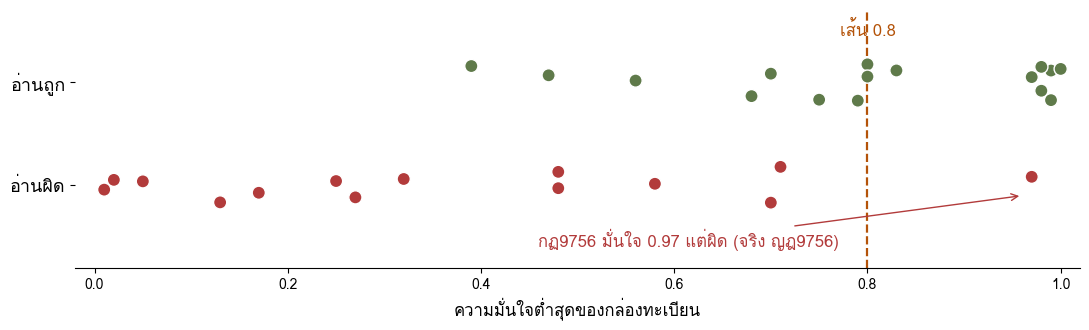

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.4))
jitter = np.random.default_rng(0).uniform(-0.18, 0.18, len(df))
ax.scatter(df.conf, df.ok.astype(int) + jitter, s=90, c=np.where(df.ok, GREEN, RED), edgecolor='white', zorder=3)
ax.axvline(0.8, ls='--', color=ORANGE, lw=1.6); ax.text(0.8, 1.45, 'เส้น 0.8', color=ORANGE, ha='center', fontsize=12)
worst = df[(~df.ok)].sort_values('conf').iloc[-1]
ax.annotate('%s มั่นใจ %.2f แต่ผิด (จริง %s)' % (worst.read, worst.conf, worst.truth), (worst.conf - 0.01, -0.1), (0.77, -0.6),
            color=RED, fontsize=12, ha='right', arrowprops=dict(arrowstyle='->', color=RED))
ax.set_yticks([0, 1]); ax.set_yticklabels(['อ่านผิด', 'อ่านถูก'], fontsize=13); ax.set_ylim(-0.8, 1.7); ax.set_xlim(-0.02, 1.02)
ax.set_xlabel('ความมั่นใจต่ำสุดของกล่องทะเบียน', fontsize=12)
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

ด่านที่ 5 ขยับขอบกรอบ คำตอบเปลี่ยน

In [13]:
PADS = [0, 2, 4, 6, 8, 10, 12]
hits, READS, SCORE = {}, {}, []                   # hits[file] = [ถูกไหม ที่แต่ละขอบเผื่อ]
for pad in PADS:
    n_ok = 0
    for p in test_imgs:
        crop = crop_plate(p, BOX[p], pad)
        reg, _, _ = parse(reader.readtext(np.array(crop)), crop.height)
        ok = reg == LABEL[os.path.basename(p)]['registration']
        hits.setdefault(p, []).append(ok); READS.setdefault(p, []).append(reg); n_ok += ok
    SCORE.append(n_ok); print('เผื่อขอบ %2d จุด  อ่านถูก %d/30' % (pad, n_ok))
always = [p for p, h in hits.items() if all(h)]
never = [p for p, h in hits.items() if not any(h)]
flip = [p for p, h in hits.items() if any(h) and not all(h)]
print('ถูกทุกครั้ง %d ใบ  ผิดทุกครั้ง %d ใบ  แกว่ง %d ใบ' % (len(always), len(never), len(flip)))
for p in flip: print('  แกว่ง', os.path.basename(p)[:14], LABEL[os.path.basename(p)]['registration'], ''.join('O' if h else 'X' for h in hits[p]))

เผื่อขอบ  0 จุด  อ่านถูก 16/30
เผื่อขอบ  2 จุด  อ่านถูก 14/30
เผื่อขอบ  4 จุด  อ่านถูก 13/30
เผื่อขอบ  6 จุด  อ่านถูก 16/30
เผื่อขอบ  8 จุด  อ่านถูก 16/30
เผื่อขอบ 10 จุด  อ่านถูก 14/30
เผื่อขอบ 12 จุด  อ่านถูก 16/30
ถูกทุกครั้ง 10 ใบ  ผิดทุกครั้ง 13 ใบ  แกว่ง 7 ใบ
  แกว่ง 20220728170739 9กฮ5961 OXOOOOO
  แกว่ง 20220916113635 9กด9225 OXXOXXX
  แกว่ง 20220921114511 5กบ1024 OOXOOXO
  แกว่ง 20220921120802 8กฎ2673 OOXOOOO
  แกว่ง 20220924155029 7กณ9943 XOXOOXO
  แกว่ง 20221007154203 กจ9181 OXOOOOO
  แกว่ง 20221112161143 ศจ9466 OOOXOOO


/tmp/ipykernel_1460/2075823547.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


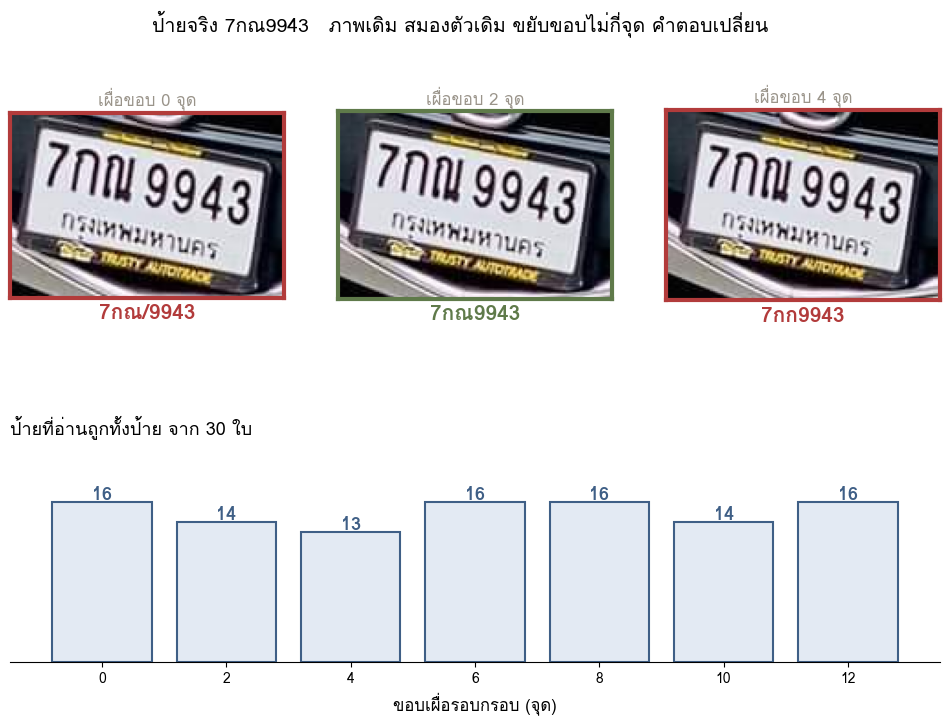

In [14]:
p = next((q for q in flip if LABEL[os.path.basename(q)]['registration'] == '7กณ9943'), flip[0])
fig = plt.figure(figsize=(12, 7.5)); gs = fig.add_gridspec(2, 3, height_ratios=[1.1, 1], hspace=0.5)
for i, pad in enumerate(PADS[:3]):
    ax = fig.add_subplot(gs[0, i]); ax.imshow(crop_plate(p, BOX[p], pad)); ax.set_xticks([]); ax.set_yticks([])
    c = GREEN if hits[p][i] else RED
    for sp in ax.spines.values(): sp.set_edgecolor(c); sp.set_linewidth(3)
    ax.set_title('เผื่อขอบ %d จุด' % pad, fontsize=12, color=GRAY); ax.set_xlabel(READS[p][i], fontsize=15, color=c, fontweight='bold')
ax = fig.add_subplot(gs[1, :])
bars = ax.bar([str(x) for x in PADS], SCORE, color='#e3eaf3', edgecolor='#3f5f86', linewidth=1.5)
for b, v in zip(bars, SCORE): ax.text(b.get_x() + b.get_width() / 2, v + 0.3, str(v), ha='center', fontsize=13, color='#3f5f86', fontweight='bold')
ax.set_ylim(0, 22); ax.set_yticks([]); ax.set_xlabel('ขอบเผื่อรอบกรอบ (จุด)', fontsize=12); ax.set_title('ป้ายที่อ่านถูกทั้งป้าย จาก 30 ใบ', fontsize=13, loc='left')
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
fig.suptitle('ป้ายจริง %s   ภาพเดิม สมองตัวเดิม ขยับขอบไม่กี่จุด คำตอบเปลี่ยน' % LABEL[os.path.basename(p)]['registration'], fontsize=14)
plt.tight_layout(); plt.show()

ด่านที่ 6 ถ่ายหลายใบแล้วโหวต

In [15]:
groups = df.groupby('truth')
for truth, g in groups:
    if len(g) < 2: continue
    reads = list(g.read)
    verdict = 'ตรงกัน ' + ('และถูก' if reads[0] == truth else 'แต่ผิด') if len(set(reads)) == 1 else 'ไม่ตรงกัน ถือว่าไม่แน่ใจ'
    print('รถ %-8s ถ่าย %d ครั้ง อ่านได้ %-28s %s' % (truth, len(g), ' / '.join(reads), verdict))

รถ 1ขจ5916  ถ่าย 2 ครั้ง อ่านได้ 1ขา5915 / 1ขา5916            ไม่ตรงกัน ถือว่าไม่แน่ใจ
รถ 7กล9108  ถ่าย 2 ครั้ง อ่านได้ 7กล9108 / 7กล9108            ตรงกัน และถูก
รถ 9กฮ5961  ถ่าย 3 ครั้ง อ่านได้ 9กฮ5961 / 9กฮ5961 / 9กฮ5961  ตรงกัน และถูก
รถ ฌน9833   ถ่าย 2 ครั้ง อ่านได้ ญน9833 / ฌน9833              ไม่ตรงกัน ถือว่าไม่แน่ใจ


ด่านที่ 7 ไม้กั้นจำลองที่ผิดแบบปลอดภัย

In [16]:
MEMBERS = {'7กล9108', '9กฮ5961', 'ขท3329', '1ขจ5916', 'ฌน9833', 'ศจ9466'}   # รายชื่อสมมติ 6 ทะเบียน

def decide(read):
    return 'เปิดไม้กั้น' if read in MEMBERS else 'เรียกเจ้าหน้าที่'

df['member'] = df.truth.isin(MEMBERS)
df['action'] = df.read.map(decide)
opened = df[df.action == 'เปิดไม้กั้น']
print('รถสมาชิกโผล่มา %d ครั้ง จากทั้งหมด 30 ครั้ง' % df.member.sum())
print('เปิดไม้กั้น %d ครั้ง  ในนั้นเปิดผิดคน %d ครั้ง' % (len(opened), (opened.read != opened.truth).sum()))
print('สมาชิกที่ต้องเรียกเจ้าหน้าที่ %d ครั้ง' % (df.member & (df.action != 'เปิดไม้กั้น')).sum())
print('คนนอกที่ถูกเปิดให้ %d ครั้ง' % (~df.member & (df.action == 'เปิดไม้กั้น')).sum())
print(df[df.member][['file', 'read', 'truth', 'action']].to_string(index=False))

รถสมาชิกโผล่มา 11 ครั้ง จากทั้งหมด 30 ครั้ง
เปิดไม้กั้น 8 ครั้ง  ในนั้นเปิดผิดคน 0 ครั้ง
สมาชิกที่ต้องเรียกเจ้าหน้าที่ 3 ครั้ง
คนนอกที่ถูกเปิดให้ 0 ครั้ง
          file    read   truth           action
20220516203717 7กล9108 7กล9108      เปิดไม้กั้น
20220516203721 7กล9108 7กล9108      เปิดไม้กั้น
20220728170738 9กฮ5961 9กฮ5961      เปิดไม้กั้น
20220728170738 9กฮ5961 9กฮ5961      เปิดไม้กั้น
20220728170739 9กฮ5961 9กฮ5961      เปิดไม้กั้น
20220918144959  ขท3329  ขท3329      เปิดไม้กั้น
20221002161313 1ขา5915 1ขจ5916 เรียกเจ้าหน้าที่
20221002161320 1ขา5916 1ขจ5916 เรียกเจ้าหน้าที่
20221007144147  ญน9833  ฌน9833 เรียกเจ้าหน้าที่
20221007144148  ฌน9833  ฌน9833      เปิดไม้กั้น
20221112161143  ศจ9466  ศจ9466      เปิดไม้กั้น
